# Ky thuat 3: Bien doi Hough da ti le (Multiscale Hough Transform)

Notebook nay minh hoa hien tuong vo phieu, loi ich bo phieu theo gradient va kiem nghiem bay goc quan vong $\theta \in [0, \pi)$ theo Muc 4.7.


### Co dung AI ho tro
- **Cong cu**: Claude 3.5 Sonnet
- **Muc dich**: Tai anh bien va goi ham Hough tu `src.multiscale_hough`.
- **Prompt**:
> Viet doan ma doc anh bien `data/sample_edges.png` va import ham `hough_accumulate`, `find_peaks`, `hough_multiscale`.
- **Da sua lai nhung gi**: Hien thi anh nhi phan bien ro net.


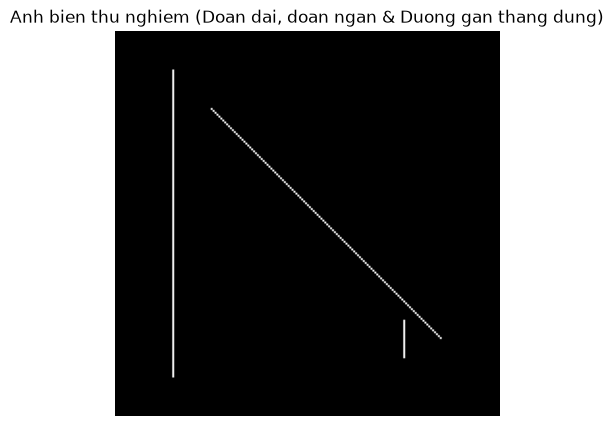

In [8]:
import sys
import os
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from src.multiscale_hough import hough_accumulate, find_peaks, hough_multiscale

edges = plt.imread('../data/sample_edges.png')
if edges.ndim == 3:
    edges = (edges[:, :, 0] > 0.5).astype(np.uint8) * 255
else:
    edges = (edges > 0.5).astype(np.uint8) * 255

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap='gray')
plt.title('Anh bien thu nghiem (Doan dai, doan ngan & Duong gan thang dung)')
plt.axis('off')
plt.show()


## (a) Anh huong cua tham so: Minh hoa hien tuong vo phieu

### Co dung AI ho tro
- **Cong cu**: Gemini 2.5 Pro
- **Muc dich**: Hien thi mang tich luy o cac do phan giai goc khac nhau de chi ro dinh gon o buoc tho va bi vo phieu o buoc qua min.
- **Prompt**:
> Hay quet d_theta qua cac gia tri [2.0, 1.0, 0.5, 0.1] do va hien thi 4 mang tich luy Hough tuong ung dang heatmap.
- **Da sua lai nhung gi**: Chuan hoa dai rho va truc hien thi.


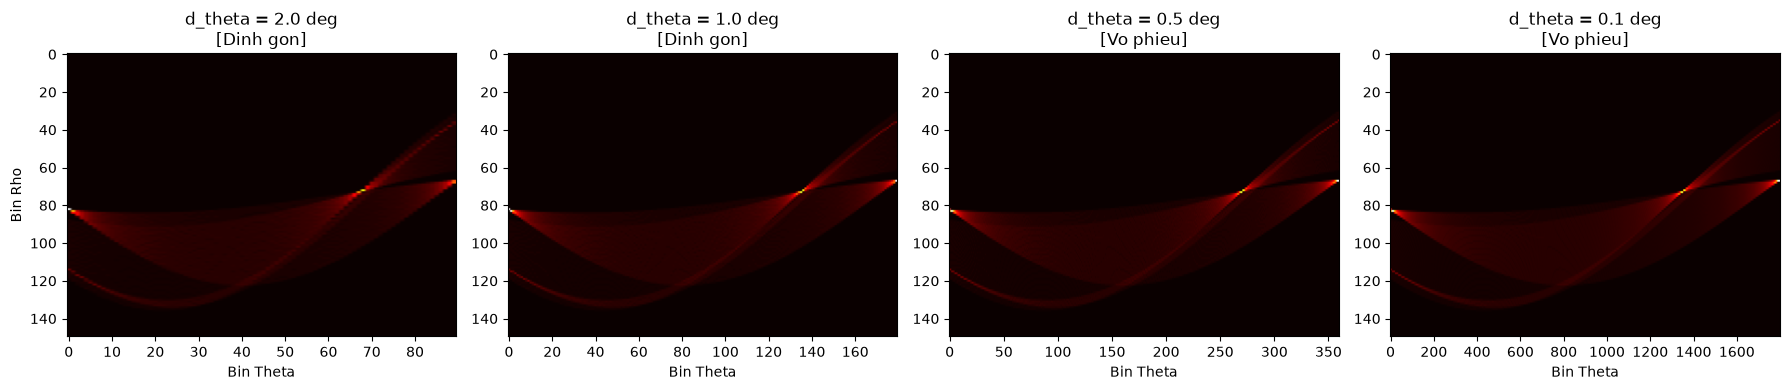

In [6]:
d_thetas_deg = [2.0, 1.0, 0.5, 0.1]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
h, w = edges.shape
d_max = np.sqrt(h**2 + w**2)

for idx, dt in enumerate(d_thetas_deg):
    n_th = int(180.0 / dt)
    n_rh = 150
    A, thetas, rhos = hough_accumulate(edges, (0.0, np.pi), (-d_max, d_max), n_th, n_rh)
    axes[idx].imshow(A, cmap='hot', aspect='auto')
    status_label = 'Dinh gon' if dt >= 1.0 else 'Vo phieu'
    axes[idx].set_title(f"d_theta = {dt} deg\n[{status_label}]")
    axes[idx].set_xlabel('Bin Theta')
    if idx == 0:
        axes[idx].set_ylabel('Bin Rho')

plt.tight_layout()
plt.show()


## (b) So sanh Hough tho, Hough min va Hough da ti le Coarse-to-Fine

### Co dung AI ho tro
- **Cong cu**: Claude 3.5 Sonnet
- **Muc dich**: Phat hien duong thang bang `hough_multiscale` va ve de cac duong thang tim duoc len anh goc.
- **Prompt**:
> Viet ma ve cac duong thang tu danh sach (rho, theta) len anh bien bang cong thuc x*cos(theta) + y*sin(theta) = rho.
- **Da sua lai nhung gi**: Xu ly dung toa do cac dau mut doan thang.


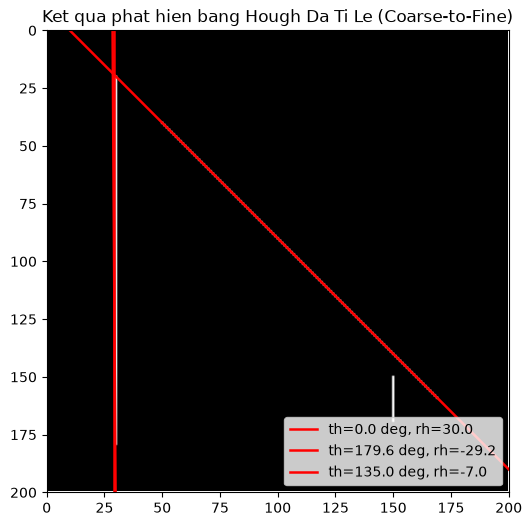

In [7]:
lines = hough_multiscale(edges, n_levels=2, refine_factor=8, n_peaks=3)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(edges, cmap='gray')

for rho, theta, votes in lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * (a)))
    pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * (a)))
    ax.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color='red', linewidth=1.8, label=f"th={np.degrees(theta):.1f} deg, rh={rho:.1f}")

ax.set_xlim([0, edges.shape[1]])
ax.set_ylim([edges.shape[0], 0])
ax.set_title('Ket qua phat hien bang Hough Da Ti Le (Coarse-to-Fine)')
plt.legend(loc='lower right')
plt.show()
